# Phase 3: Preliminary Data Analysis and Feasibility

**Using Transformers to Extract Sentiment Signals from Financial News for Stock Prediction**

CS 450-04, Advanced AI, Fall 2026 · Dr. Benyamin Haghi, SDSU

Jason Auston, Brianna Garcia, Anthony Nguyen, Maggi Savajiyani, Harish Raaj Sivakumar

---

This notebook reproduces every number and figure in the Phase 3 report from the
derived files committed to the repository. The raw FNSPID shards (800 MB) are not
redistributed; cells that need them are guarded and fall back to recorded values.

All parquet I/O goes through DuckDB. `pyarrow` is broken in our Anaconda environment
(`liborc.dylib` expects a protobuf symbol the installed `libprotobuf` does not export),
so `pandas.read_parquet` and `to_parquet` are unavailable.

In [1]:
import os, json
from pathlib import Path
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import statsmodels.api as sm

# find the repo root by walking up until we see data/ - works from anywhere
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir()),
            Path.cwd())
DATA, FIGS = ROOT / "data", ROOT / "figs"
FIGS.mkdir(exist_ok=True)

RAW = sorted(DATA.glob("train-*.parquet"))
RAW_AVAILABLE = len(RAW) == 2
print("repo root :", ROOT)
print("raw shards:", "present" if RAW_AVAILABLE else "absent (using recorded values)")

plt.style.use("default")   # PyCharm injects a dark theme; figures must print light
BLUE = "#3B6EA5"
plt.rcParams.update({"figure.dpi": 130, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.5,
                     "axes.spines.top": False, "axes.spines.right": False})

q = lambda s: duckdb.sql(s).df()
P = lambda name: (DATA / name).as_posix()

repo root : /Users/jasonauston/cs450
raw shards: present


## 1. Dataset

Source: FNSPID, filtered NASDAQ-100 subset
([benstaf/FNSPID-filtered-nasdaq-100](https://huggingface.co/datasets/benstaf/FNSPID-filtered-nasdaq-100)),
CC BY-NC-4.0. Prices from Yahoo Finance via `yfinance`, split and dividend adjusted.

The raw subset is 358,154 rows and 12 columns, all typed `VARCHAR`. Its true coverage is
**2009-07-07 to 2024-01-09**, not the 1999-2023 range the FNSPID paper describes.

In [2]:
if RAW_AVAILABLE:
    raw = P("train-*.parquet")
    display(q(f"DESCRIBE SELECT * FROM read_parquet('{raw}')"))
    display(q(f"""SELECT count(*) AS rows, min(Date) AS first, max(Date) AS last
                  FROM read_parquet('{raw}')"""))
else:
    print("raw shards absent - recorded values:")
    print("  rows 358,154 | columns 12 (all VARCHAR)")
    print("  coverage 2009-07-07 .. 2024-01-09")

,column_name,column_type,null,key,default,extra
0,Unnamed: 0,VARCHAR,YES,None,None,None
1,Date,VARCHAR,YES,None,None,None
2,Article_title,VARCHAR,YES,None,None,None
3,Stock_symbol,VARCHAR,YES,None,None,None
4,Url,VARCHAR,YES,None,None,None
5,Publisher,VARCHAR,YES,None,None,None
6,Author,VARCHAR,YES,None,None,None
7,Article,VARCHAR,YES,None,None,None
8,Lsa_summary,VARCHAR,YES,None,None,None
9,Luhn_summary,VARCHAR,YES,None,None,None


,rows,first,last
0,358154,2009-07-07 00:00:00 UTC,2024-01-09 00:00:00 UTC


### 1.1 Timestamp granularity: the finding that shapes everything downstream

`Date` *looks* like a timestamp (`2023-12-16 22:00:00 UTC`, length 23 on every row) but
**357,452 of 358,154 rows (99.8%) have minutes and seconds at `00:00`**, and
**357,192 (99.7%) sit at hour `00`**. It is a date-only field in timestamp clothing.

Consequence: we cannot establish that a headline preceded an intraday move, so the
alignment rule in section 4 has to be conservative.

In [3]:
if RAW_AVAILABLE:
    raw = P("train-*.parquet")
    display(q(f"""SELECT substr(Date,12,2) AS hour_utc, count(*) AS n
                  FROM read_parquet('{raw}') GROUP BY 1 ORDER BY n DESC LIMIT 5"""))
else:
    print("recorded: hour 00 -> 357,192 of 358,154 rows (99.7%)")
    print("          min:sec 00:00 -> 357,452 (99.8%)")

,hour_utc,n
0,00,357192
1,06,147
2,05,108
3,04,107
4,07,81


### 1.2 Cleaning funnel

| Step | Rows |
|---|---|
| raw subset | 358,154 |
| top-25 tickers, 2019-2023, roundups dropped, deduped | 119,527 |
| after dropping two delisted tickers (EA, WBA) | **113,075** |

Filters applied, each traced to a finding in section 2: three recurring roundup patterns
(5,116 rows, 1.43%), exact duplicates on (date, ticker, headline) (8.98%), and the
`Date` string cast to a real `DATE`.

In [4]:
summary = q(f"""
  SELECT count(*) AS rows,
         count(DISTINCT Stock_symbol) AS tickers,
         count(DISTINCT Article_title) AS unique_headlines,
         min(pub_date) AS first, max(pub_date) AS last
  FROM read_parquet('{P("panel.parquet")}')""")
display(summary)

,rows,tickers,unique_headlines,first,last
0,113075,23,83470,2019-01-01,2023-12-31


### 1.3 Low-information headline patterns (Table I)

Recurring wire roundups list many tickers at once and carry dates that disagree with
their own content, so they are dropped in preprocessing. Counted on the raw subset;
when the shards are absent the recorded values are used.


In [5]:
PATTERNS = ["%Most Active for%", "%Company News for%", "%Stock Market News for%"]

if RAW_AVAILABLE:
    raw = P("train-*.parquet")
    counts = [q(f"""SELECT count(*) AS n FROM read_parquet('{raw}')
                    WHERE Article_title LIKE '{pat}'""").n[0] for pat in PATTERNS]
else:
    counts = [3682, 622, 812]

tbl1 = pd.DataFrame({"Pattern": PATTERNS, "Rows": counts})
total = int(tbl1.Rows.sum())
tbl1["Share"] = (tbl1.Rows / 358154 * 100).round(2).astype(str) + "%"
tbl1.loc[len(tbl1)] = ["Total", total, f"{total/358154*100:.2f}%"]
display(tbl1.style.hide(axis="index"))
print(f"{total:,} of 358,154 raw rows = {total/358154*100:.2f}%")

Pattern,Rows,Share
%Most Active for%,3682,1.03%
%Company News for%,622,0.17%
%Stock Market News for%,812,0.23%
Total,5116,1.43%


5,116 of 358,154 raw rows = 1.43%


## 2. Preliminary EDA
### 2.1 Coverage over time

Note the dip in 2021 (19,795 articles against 41,343 in 2019 and 63,902 in 2023).
Coverage is not stable across the window.

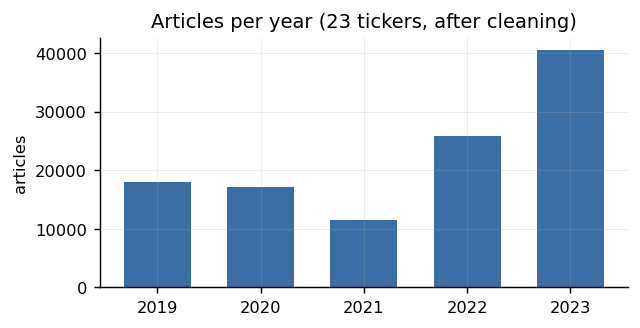

pub_date,2019,2020,2021,2022,2023
articles,18024,17148,11540,25832,40531


In [6]:
panel = q(f"SELECT * FROM read_parquet('{P('panel.parquet')}')")
panel["pub_date"] = pd.to_datetime(panel.pub_date)

yr = panel.groupby(panel.pub_date.dt.year).size()
plt.figure(figsize=(5,2.6)); plt.bar(yr.index, yr.values, color=BLUE, width=.65)
plt.title("Articles per year (23 tickers, after cleaning)"); plt.ylabel("articles")
plt.tight_layout(); plt.savefig(FIGS/"fig1_coverage_by_year.png", bbox_inches="tight"); plt.show()
display(yr.to_frame("articles").T)

### 2.2 Ticker composition

23 tickers after dropping EA and WBA. Volume spread is roughly 6x, far milder than the
50x skew a naive "AAPL dominates" assumption would predict.

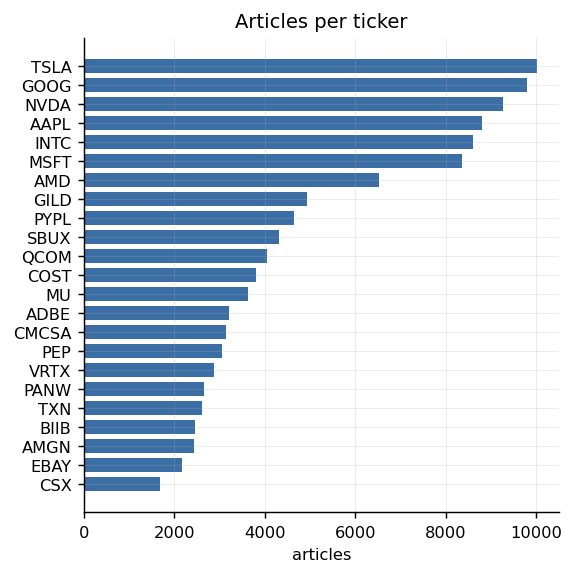

max 10,017 (TSLA)  min 1,669 (CSX)  ratio 6.0x


In [7]:
tk = panel.groupby("Stock_symbol").size().sort_values()
plt.figure(figsize=(4.5,4.5)); plt.barh(tk.index, tk.values, color=BLUE, height=.7)
plt.title("Articles per ticker"); plt.xlabel("articles")
plt.tight_layout(); plt.savefig(FIGS/"supp_articles_per_ticker.png", bbox_inches="tight"); plt.show()
print(f"max {tk.max():,} ({tk.idxmax()})  min {tk.min():,} ({tk.idxmin()})  ratio {tk.max()/tk.min():.1f}x")

### 2.3 Quality problems

**Missingness.** `Publisher` is empty on 225,187 of 358,154 raw rows (62.9%), which rules
out publisher-based filtering.

**Duplication and cross-attribution.** The raw subset has 265,585 distinct headlines
across 358,154 rows. Splitting that: 32,159 rows (8.98%) are true duplicates (same
headline *and* ticker), while 60,410 (16.87%) come from one headline being filed under
several tickers, one headline appears under **51** different symbols.

**Mis-attribution.** Of the 49,306 raw headlines containing a parenthesized ticker,
**24,769 (50.2%) do not contain the filed `Stock_symbol` anywhere**. Example:
*"NVIDIA (NVDA) Up 243% YTD: Will It Carry Momentum in 2024?"* filed under `AAPL`.

*Caveat:* ticker-string matching undercounts relevance badly, since most headlines name
companies in words ("Apple Unveils New iPhone"). The defensible claim is the 50.2%
figure restricted to headlines that use ticker symbols. Company-name matching is Phase 4.

In [8]:
print("headlines whose filed ticker appears in the title (weak proxy):")
display(panel.symbol_in_title.value_counts(normalize=True).rename("share").to_frame().round(3))

print("\nexample of cross-filing:")
display(panel[panel.Article_title.str.contains("NVIDIA", na=False) &
              (panel.Stock_symbol == "AAPL")][["pub_date","Stock_symbol","Article_title"]].head(3))

headlines whose filed ticker appears in the title (weak proxy):


,share
symbol_in_title,
False,0.829
True,0.171



example of cross-filing:


,pub_date,Stock_symbol,Article_title
10417,2023-11-06,AAPL,"NVIDIA, Meta & 2023's Best-Performing ETFs"
10453,2023-11-08,AAPL,"1 Semiconductor Stock Set to Join Apple, Amazo..."
11006,2023-12-16,AAPL,NVIDIA (NVDA) Up 243% YTD: Will It Carry Momen...


### 2.4 Headline length: justifies headlines-only and `max_length=64`

Mean 61 characters, p95 96, max 396. Roughly 15 tokens typical and under 100 worst case,
against BERT's 512-token limit. Scoring headlines rather than article bodies costs almost
no information at the token level and cuts inference cost by orders of magnitude.

min 10  mean 61  p95 95  max 387


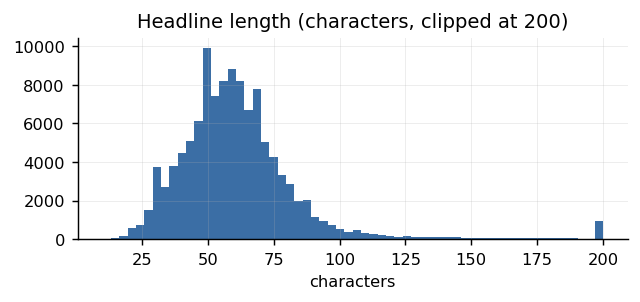

In [9]:
L = panel.Article_title.str.len()
print(f"min {L.min()}  mean {L.mean():.0f}  p95 {L.quantile(.95):.0f}  max {L.max()}")
plt.figure(figsize=(5,2.4)); plt.hist(L.clip(upper=200), bins=60, color=BLUE)
plt.title("Headline length (characters, clipped at 200)"); plt.xlabel("characters")
plt.tight_layout(); plt.savefig(FIGS/"fig2_headline_length.png", bbox_inches="tight"); plt.show()

### 2.5 Sparsity: a third of ticker-days carry a single article

This matters for the strength score defined in Phase 2 (mean of signed class
probabilities, described as reflecting how *consistently* the day's news skewed). On a
single-article day there is no consistency to measure; the score collapses to one
article's probability.

ticker-days: 21,895


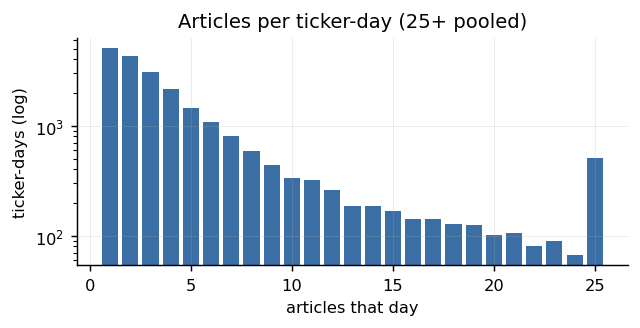

single-article ticker-days: 5,056 (23.1%)


In [10]:
agg = q(f"SELECT * FROM read_parquet('{P('ticker_day.parquet')}')")
agg["trade_date"] = pd.to_datetime(agg.trade_date)
print(f"ticker-days: {len(agg):,}")

h = agg.n_articles.clip(upper=25).value_counts().sort_index()
plt.figure(figsize=(5,2.6)); plt.bar(h.index, h.values, color=BLUE, width=.8)
plt.yscale("log"); plt.title("Articles per ticker-day (25+ pooled)")
plt.xlabel("articles that day"); plt.ylabel("ticker-days (log)")
plt.tight_layout(); plt.savefig(FIGS/"fig3_articles_per_ticker_day.png", bbox_inches="tight"); plt.show()

print(f"single-article ticker-days: {(agg.n_articles==1).sum():,} "
      f"({(agg.n_articles==1).mean()*100:.1f}%)")

### 2.6 Sentiment class distribution

FinBERT (`ProsusAI/finbert`, off the shelf) scored all 83,470 unique headlines on MPS.
Scoring distinct text rather than every row saved 29,605 forward passes.

Nearly two thirds of headlines are neutral. **Accuracy is therefore useless as a metric**
against a 62.6% majority class, which is why the evaluation plan leads with macro-F1.

,count,share
fin_label,,
positive,17597,0.211
neutral,52238,0.626
negative,13635,0.163


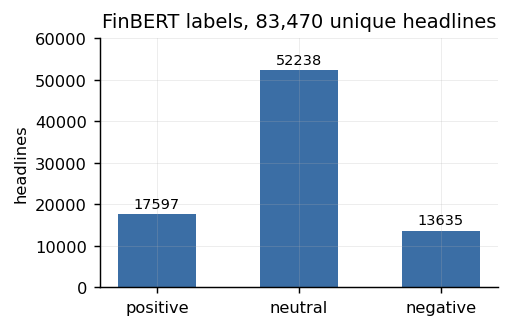

count    83470.0000
mean         0.0625
std          0.4861
min         -0.9692
25%         -0.0229
50%          0.0417
75%          0.2495
max          0.9454


In [11]:
sent = q(f"SELECT * FROM read_parquet('{P('sentiment.parquet')}')")
vc = sent.fin_label.value_counts().reindex(["positive","neutral","negative"])
display(pd.DataFrame({"count": vc, "share": (vc/len(sent)).round(3)}))

plt.figure(figsize=(4,2.6)); b = plt.bar(vc.index, vc.values, color=BLUE, width=.55)
plt.bar_label(b, fmt="%d", padding=2, fontsize=8)
plt.title(f"FinBERT labels, {len(sent):,} unique headlines"); plt.ylabel("headlines")
plt.margins(y=.15); plt.tight_layout()
plt.savefig(FIGS/"supp_class_distribution.png", bbox_inches="tight"); plt.show()

print(sent.sent_score.describe().round(4).to_string())

### 2.7 Return distribution and extreme moves

Every one of the ten largest moves is a verifiable event, so there are no unadjusted
splits contaminating the labels. **Biogen accounts for six of the ten**, one ticker out
of 23 dominates both tails, because biotech runs on binary trial outcomes. Pooled metrics
will be sensitive to a handful of BIIB days, so results should be reported per ticker as
well as pooled.

count    29555.00000
mean         0.00095
std          0.02401
min         -0.29230
25%         -0.00979
50%          0.00078
75%          0.01167
max          0.43974


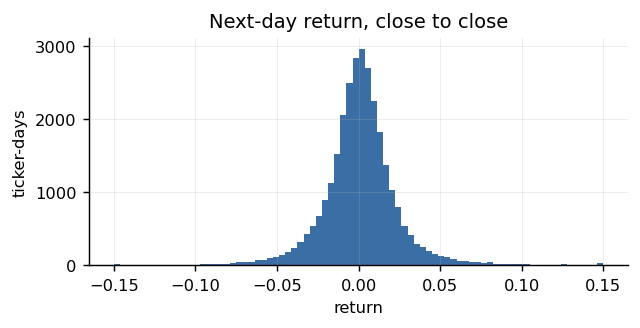

,trade_date,Stock_symbol,fwd_return_%
0,2020-11-03,BIIB,44.0
1,2022-09-27,BIIB,39.9
2,2021-06-04,BIIB,38.3
3,2019-10-21,BIIB,26.1
4,2023-05-24,NVDA,24.4
5,2019-03-20,BIIB,-29.2
6,2020-11-06,BIIB,-28.2
7,2022-02-01,PYPL,-24.6
8,2020-09-04,TSLA,-21.1
9,2020-10-14,VRTX,-20.7



per-ticker daily volatility (std of next-day return), top 5:
Stock_symbol
TSLA    0.0407
AMD     0.0340
NVDA    0.0326
BIIB    0.0312
MU      0.0288


In [12]:
ret = q(f"SELECT * FROM read_parquet('{P('returns.parquet')}')")
print(ret.fwd_ret_1d.describe().round(5).to_string())

plt.figure(figsize=(5,2.6)); plt.hist(ret.fwd_ret_1d.clip(-.15,.15), bins=80, color=BLUE)
plt.title("Next-day return, close to close"); plt.xlabel("return"); plt.ylabel("ticker-days")
plt.tight_layout(); plt.savefig(FIGS/"fig4_return_distribution.png", bbox_inches="tight"); plt.show()

ext = pd.concat([ret.nlargest(5,"fwd_ret_1d"), ret.nsmallest(5,"fwd_ret_1d")])
ext["fwd_ret_1d"] = (ext.fwd_ret_1d*100).round(1)
display(ext.rename(columns={"fwd_ret_1d":"fwd_return_%"})
           .reset_index(drop=True))
print("\nper-ticker daily volatility (std of next-day return), top 5:")
print(ret.groupby("Stock_symbol").fwd_ret_1d.std().nlargest(5).round(4).to_string())

## 3. Preprocessing plan

Each step below exists because of a specific finding above, not as generic hygiene.

| Step | Driven by |
|---|---|
| drop `Unnamed: 0` | leftover pandas index column |
| drop 3 roundup patterns (5,116 rows, 1.43%) | ticker-list headlines with dates off by 1-3 days |
| `SELECT DISTINCT` on (date, ticker, headline) | 8.98% true duplicates |
| cast `Date` → `DATE`, discard the time | 99.7% of timestamps are `00:00` |
| carry `symbol_in_title`, do **not** filter on it | 50.2% paren mismatch, but ticker matching undercounts relevance |
| restrict to top 25 tickers, 2019-2023 | coverage density; 2021 dip documented |
| tokenize at `max_length=64` | p95 headline = 96 characters |
| score distinct headlines only | avoids 29,605 redundant forward passes |
| minimum-article threshold per ticker-day *(proposed)* | 33.7% single-article days |

Deferred to Phase 4: company-name matching as a relevance filter.

## 4. Alignment rule and leakage control

Each article's publication date **D** maps to **T0**, the most recent trading day at or
before D (DuckDB `ASOF JOIN`). The label is the return from `close(T0)` to the next
trading day's close.

- **D is a trading day** → we claim only `close(D) → close(D+1)`. An article published
  mid-session cannot be credited with that session's move.
- **D is a weekend or holiday** → T0 is the prior Friday, so the label is
  `Friday close → Monday close`, capturing the weekend-news effect with no leakage.

The trailing-volatility control in section 5.3 uses a 20-day rolling standard deviation
computed **through T0 only**.

Join integrity: 113,075 rows in, 113,075 out. 10,574 articles (9.4%) published on
non-trading days, mean lag 0.153 days.

In [13]:
chk = q(f"""SELECT count(*) AS rows,
                    count(*) FILTER (WHERE pub_date <> trade_date) AS nontrading_day_news,
                    round(avg(date_diff('day', trade_date, pub_date)),3) AS avg_lag_days
             FROM read_parquet('{P('panel.parquet')}')""")
display(chk)

,rows,nontrading_day_news,avg_lag_days
0,113075,10574,0.153


## 5. Preliminary results
### 5.1 Direction: null, four independent ways

The Phase 2 hypothesis was that positive sentiment precedes upward movement. It does not,
at a daily horizon, in this data.

In [14]:
r_p, p_p = pearsonr(agg.sent_mean, agg.fwd_ret_1d)
r_s = agg.sent_mean.corr(agg.fwd_ret_1d, method="spearman")
dir_ok = (np.sign(agg.sent_mean) == np.sign(agg.fwd_ret_1d)).mean()
base   = (agg.fwd_ret_1d > 0).mean()

print(f"ticker-days          : {len(agg):,}")
print(f"Pearson              : {r_p:+.4f}  (p={p_p:.3f})")
print(f"Spearman             : {r_s:+.4f}")
print(f"direction agreement  : {dir_ok*100:.2f}%")
print(f"always-up baseline   : {base*100:.2f}%")
print(f"\n-> sentiment sign does {'WORSE' if dir_ok < base else 'better'} than always guessing up")

ticker-days          : 21,895
Pearson              : -0.0042  (p=0.533)
Spearman             : -0.0035
direction agreement  : 50.97%
always-up baseline   : 52.01%

-> sentiment sign does WORSE than always guessing up


Split by news volume, the pattern is **not** monotonic, and with four tests the Bonferroni
threshold is 0.0125. The only bucket clearing it has the **wrong sign**. This is noise,
not a weak signal.

,bucket,n,pearson,p,passes_bonferroni_0.0125
0,1,5056,-0.0030,0.8298,False
1,2-4,9540,-0.0261,0.0109,True
2,5-15,5807,0.0177,0.1769,False
3,16+,1492,0.0545,0.0353,False


per-ticker Pearson range: -0.0511 .. +0.0658
SE(r) at ~951 obs/ticker: 0.0325  -> extremes are ~2.0 SE, consistent with zero


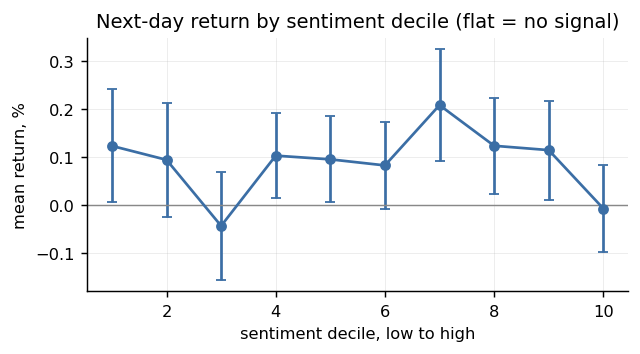

In [15]:
agg["bucket"] = pd.cut(agg.n_articles, [0,1,4,15,10**6], labels=["1","2-4","5-15","16+"])
rows = []
for b, g in agg.groupby("bucket", observed=True):
    r, p = pearsonr(g.sent_mean, g.fwd_ret_1d)
    rows.append({"bucket": b, "n": len(g), "pearson": round(r,4), "p": round(p,4),
                 "passes_bonferroni_0.0125": p < 0.0125})
display(pd.DataFrame(rows))

pt = agg.groupby("Stock_symbol").apply(
        lambda g: g.sent_mean.corr(g.fwd_ret_1d), include_groups=False)
se = 1/np.sqrt(len(agg)/agg.Stock_symbol.nunique() - 3)
print(f"per-ticker Pearson range: {pt.min():+.4f} .. {pt.max():+.4f}")
print(f"SE(r) at ~{len(agg)//agg.Stock_symbol.nunique()} obs/ticker: {se:.4f}"
      f"  -> extremes are ~{pt.abs().max()/se:.1f} SE, consistent with zero")

plt.figure(figsize=(5,2.8))
agg["dec"] = pd.qcut(agg.sent_mean, 10, labels=False, duplicates="drop")
gg = agg.groupby("dec").fwd_ret_1d
m2, s2 = gg.mean(), gg.std()/np.sqrt(gg.count())
plt.errorbar(m2.index+1, m2.values*100, yerr=s2.values*196, fmt="o-",
             color=BLUE, ms=5, lw=1.5, capsize=3)
plt.axhline(0, color="#888", lw=.8)
plt.title("Next-day return by sentiment decile (flat = no signal)")
plt.xlabel("sentiment decile, low to high"); plt.ylabel("mean return, %")
plt.tight_layout(); plt.savefig(FIGS/"supp_sentiment_decile_null.png", bbox_inches="tight"); plt.show()

### 5.2 Magnitude: strong, significant, monotonic

Sentiment cannot say *which way* a stock moves. News **volume** says a great deal about
*how far* it moves. Note that it is the amount of coverage that carries the information,
not its tone: `|sentiment|` is only marginally related (p = 0.066).

     |sentiment| vs |next-day return|   r=+0.0124   p=0.0664
        articles vs |next-day return|   r=+0.1190   p=6.57e-70
 log1p(articles) vs |next-day return|   r=+0.1364   p=1.87e-91


,mean_abs_return_%,n
bucket,,
1,1.376,5056
2-4,1.511,9540
5-15,1.892,5807
16+,2.176,1492


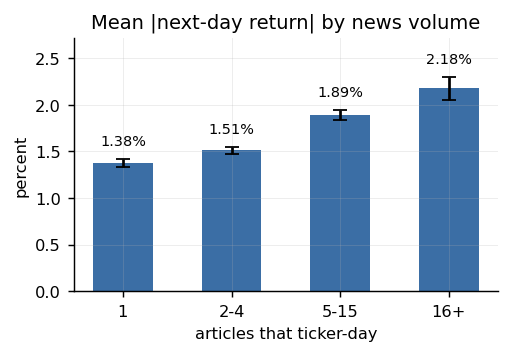

spread: 1.58x from quietest to noisiest news days


In [16]:
agg["abs_ret"]  = agg.fwd_ret_1d.abs()
agg["abs_sent"] = agg.sent_mean.abs()
agg["log_art"]  = np.log1p(agg.n_articles)

for col, label in [("abs_sent","|sentiment|"), ("n_articles","articles"),
                   ("log_art","log1p(articles)")]:
    r, p = pearsonr(agg[col], agg.abs_ret)
    print(f"{label:>16} vs |next-day return|   r={r:+.4f}   p={p:.3g}")

g = agg.groupby("bucket", observed=True).abs_ret
mu, se_ = g.mean(), g.std()/np.sqrt(g.count())
display(pd.DataFrame({"mean_abs_return_%": (mu*100).round(3), "n": g.count()}))

plt.figure(figsize=(4,2.8))
b = plt.bar(mu.index.astype(str), mu.values*100, yerr=se_.values*196,
            color=BLUE, width=.55, capsize=4)
plt.bar_label(b, fmt="%.2f%%", padding=6, fontsize=8)
plt.title("Mean |next-day return| by news volume"); plt.ylabel("percent")
plt.xlabel("articles that ticker-day"); plt.margins(y=.18)
plt.tight_layout(); plt.savefig(FIGS/"fig5_magnitude_by_volume.png", bbox_inches="tight"); plt.show()
print(f"spread: {mu.iloc[-1]/mu.iloc[0]:.2f}x from quietest to noisiest news days")

### 5.3 Robustness: does it survive a volatility control?

The obvious objection is that volatility clusters, so news volume might just proxy for
"this stock has been jumpy lately." We regress next-day absolute return on
`log1p(articles)` **and** trailing 20-day realised volatility.

Trailing volatility is reconstructed from the committed returns table: the realised return
*on* day t equals `fwd_ret_1d` at t−1, so a 20-day rolling standard deviation through T0
uses only information available at T0.

In [17]:
rr = ret.copy()
rr["trade_date"] = pd.to_datetime(rr.trade_date)
rr = rr.sort_values(["Stock_symbol","trade_date"])
rr["daily_ret"] = rr.groupby("Stock_symbol").fwd_ret_1d.shift(1)
rr["trail_vol"] = (rr.groupby("Stock_symbol").daily_ret
                     .transform(lambda s: s.rolling(20).std()))

m = agg.merge(rr[["Stock_symbol","trade_date","trail_vol"]],
              on=["Stock_symbol","trade_date"], how="inner").dropna(subset=["trail_vol"])
print(f"merged ticker-days: {len(m):,}")

X = sm.add_constant(m[["log_art","trail_vol"]])
res = sm.OLS(m.abs_ret, X).fit()
print(res.summary().tables[1])

eff = (np.log1p(16) - np.log1p(1)) * res.params["log_art"]
print(f"\n1 -> 16 articles adds {eff*100:.3f} pp to expected |move| "
      f"({eff/mu.iloc[0]*100:.0f}% above the quiet-day baseline)")

merged ticker-days: 21,872
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0030      0.000      9.245      0.000       0.002       0.004
log_art        0.0020      0.000     11.988      0.000       0.002       0.002
trail_vol      0.4837      0.010     49.636      0.000       0.465       0.503

1 -> 16 articles adds 0.432 pp to expected |move| (31% above the quiet-day baseline)


### 5.4 Horizon robustness: does a longer window rescue direction?

A reasonable objection to the null in 5.1 is that one day is too short, and sentiment
may need several days to show up in price. We test 1, 2, 3, 5, 10 and 20 trading-day
forward returns, compounded per ticker.

Direction stays null at every horizon. Raw agreement does rise with the window, but
the always-up baseline rises faster because stocks drift upward, so the gap against
baseline widens from -1.0 points at one day to -4.7 at twenty. Reporting accuracy
without a baseline would have made this look like improvement.

The magnitude result holds at every horizon, which matters more than the original
finding: a relationship that survives six window choices is not an artifact of one.

,horizon_d,n,r_direction,p_direction,agree_%,baseline_%,r_magnitude,p_magnitude,gap_pp
0,1,21895,-0.0042,0.5335,50.9705,52.0073,0.1364,0.0,-1.0368
1,2,21895,0.0056,0.4109,51.8749,53.4323,0.1342,0.0,-1.5574
2,3,21895,-0.0027,0.6851,51.4912,53.7246,0.1298,0.0,-2.2334
3,5,21895,0.0031,0.6487,51.6145,54.8436,0.1219,0.0,-3.2290
4,10,21894,-0.0030,0.6582,52.3431,56.2574,0.1161,0.0,-3.9143
5,20,21846,-0.0070,0.3012,52.9937,57.6765,0.1114,0.0,-4.6828


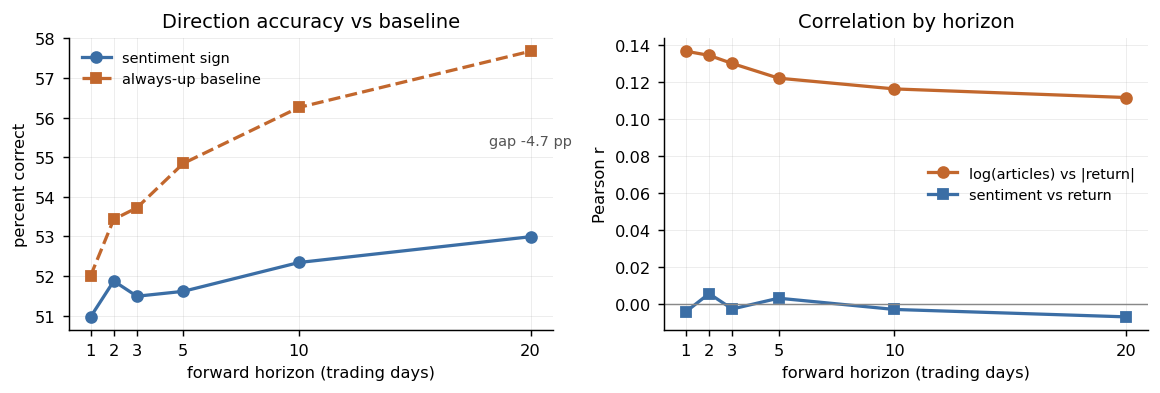

direction: r ranges -0.0070 to +0.0056, all p > 0.30
magnitude: r 0.1364 at 1d down to 0.1114 at 20d, max p = 2.6e-61
gap to baseline widens from -1.04 pp to -4.68 pp


In [18]:
# --- 5.4 horizon robustness -------------------------------------------------
from scipy.stats import pearsonr

ORANGE = "#C2672D"
HZ = [1, 2, 3, 5, 10, 20]

r_ = q(f"SELECT * FROM read_parquet('{P('returns.parquet')}')")
r_["trade_date"] = pd.to_datetime(r_.trade_date)
r_ = r_.sort_values(["Stock_symbol", "trade_date"])

# compound forward returns in log space, then convert back
for k in HZ:
    r_[f"fwd_{k}d"] = np.expm1(
        r_.groupby("Stock_symbol").fwd_ret_1d
          .transform(lambda s: np.log1p(s).rolling(k).sum().shift(-(k - 1))))

h = agg.merge(r_[["Stock_symbol", "trade_date"] + [f"fwd_{k}d" for k in HZ]],
              on=["Stock_symbol", "trade_date"], how="left")
h["log_art"] = np.log1p(h.n_articles)

rows = []
for k in HZ:
    c = f"fwd_{k}d"
    s = h.dropna(subset=[c, "sent_mean"])
    r_dir, p_dir = pearsonr(s.sent_mean, s[c])
    r_mag, p_mag = pearsonr(s.log_art, s[c].abs())
    rows.append({
        "horizon_d": k, "n": len(s),
        "r_direction": r_dir, "p_direction": p_dir,
        "agree_%": (np.sign(s.sent_mean) == np.sign(s[c])).mean() * 100,
        "baseline_%": (s[c] > 0).mean() * 100,
        "r_magnitude": r_mag, "p_magnitude": p_mag,
    })
H = pd.DataFrame(rows)
H["gap_pp"] = H["agree_%"] - H["baseline_%"]
display(H.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.1))

ax1.plot(H.horizon_d, H["agree_%"], "o-", color=BLUE, lw=1.8, ms=6,
         label="sentiment sign")
ax1.plot(H.horizon_d, H["baseline_%"], "s--", color=ORANGE, lw=1.8, ms=6,
         label="always-up baseline")
ax1.set_title("Direction accuracy vs baseline")
ax1.set_xlabel("forward horizon (trading days)")
ax1.set_ylabel("percent correct")
ax1.set_xticks(HZ)
ax1.legend(frameon=False, fontsize=8)
ax1.annotate(f"gap {H.gap_pp.iloc[-1]:+.1f} pp", xy=(20, 55.3), fontsize=8,
             ha="center", color="#555")

ax2.plot(H.horizon_d, H.r_magnitude, "o-", color=ORANGE, lw=1.8, ms=6,
         label="log(articles) vs |return|")
ax2.plot(H.horizon_d, H.r_direction, "s-", color=BLUE, lw=1.8, ms=6,
         label="sentiment vs return")
ax2.axhline(0, color="#888", lw=.8)
ax2.set_title("Correlation by horizon")
ax2.set_xlabel("forward horizon (trading days)")
ax2.set_ylabel("Pearson r")
ax2.set_xticks(HZ)
ax2.legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig(FIGS / "supp_horizon_robustness.png", bbox_inches="tight")
plt.show()

print(f"direction: r ranges {H.r_direction.min():+.4f} to {H.r_direction.max():+.4f}, "
      f"all p > {H.p_direction.min():.2f}")
print(f"magnitude: r {H.r_magnitude.max():.4f} at 1d down to {H.r_magnitude.min():.4f} "
      f"at 20d, max p = {H.p_magnitude.max():.1e}")
print(f"gap to baseline widens from {H.gap_pp.iloc[0]:+.2f} pp to {H.gap_pp.iloc[-1]:+.2f} pp")

## 6. Model and evaluation plan

**Baseline.** TF-IDF over headlines + logistic regression. Cheap, interpretable, and the
standard comparison point in the financial-NLP literature.

**Deep model.** FinBERT fine-tuned on the Financial PhraseBank sentiment corpus, then
applied to FNSPID headlines. FNSPID carries no sentiment labels, so it cannot be used as
fine-tuning data directly, a point worth stating plainly, since the Phase 2 draft implied
otherwise.

**Targets.**

1. *Primary:* next-day absolute return (magnitude). Section 5.2 shows a real, significant,
   volatility-controlled relationship here.
2. *Secondary:* next-day direction. Section 5.1 shows this is near-chance; we report it as
   a measured null rather than quietly dropping it.

**Metrics.** Macro-F1 (not accuracy, 62.6% of headlines are neutral), precision and
recall per class, Pearson and Spearman for continuous targets, plus per-ticker breakdowns
because BIIB dominates the tails.

**Validation.** Time-ordered split, never random: train 2019-2021, validate 2022,
test 2023. A random split would leak future information through overlapping news cycles
and through the cross-filed headlines documented in section 2.3.

## 7. Feasibility risks and mitigations

| Risk | Evidence from this analysis | Mitigation |
|---|---|---|
| Look-ahead / leakage | 99.7% of timestamps are `00:00`, date-only | ASOF join to T0; label is `close(T0) → close(T0+1)`; time-ordered split |
| Unreliable dates | roundup headlines off by 1-3 days from their own content | drop the three roundup patterns (1.43%) |
| Label noise / mis-attribution | 50.2% of paren-ticker headlines don't name the filed symbol; one headline filed under 51 tickers | carry `symbol_in_title`; company-name matching in Phase 4; report sensitivity |
| Class imbalance | 62.6% neutral | macro-F1 rather than accuracy; class weights |
| Direction near-unpredictable | r = −0.004; 50.97% vs a 52.01% always-up baseline | primary target moved to magnitude; direction reported as a null |
| Sparse ticker-days | 33.7% single-article days | minimum-article threshold or rolling window; publish article count beside the signal |
| Single-ticker dominance | BIIB is 6 of the 10 extreme moves | per-ticker metrics alongside pooled |
| **Survivorship bias** | EA and WBA no longer downloadable, both taken private after the news window (Walgreens/Sycamore closed Aug 2025; EA's $55B PIF-led buyout delisted it). Cost: 6,452 articles, 5.4% | documented explicitly; free price sources silently drop companies that cease to exist |
| Coverage instability | 2021 dip to 19,795; ticker ranking shifts between the full corpus and the 2019-2023 window | state the window; do not claim stable coverage |
| Compute | 83,470 headlines scored in minutes on MPS | headlines only, `max_length=64`, score distinct text |
| Tooling | `pyarrow` broken in Anaconda (`liborc.dylib` / protobuf symbol mismatch) | all parquet I/O through DuckDB |
| Licensing | FNSPID is CC BY-NC-4.0 | non-commercial coursework use; raw shards not redistributed |

## 8. Summary

The pipeline runs end to end and the data is well enough understood to commit to a model
plan. The central finding of Phase 3 is that our original Phase 2 hypothesis is not
supported, daily sentiment does not predict next-day direction, and the sentiment sign
performs slightly worse than always guessing up, while an adjacent and more tractable
target is strongly supported: news volume predicts the *magnitude* of the next day's move,
monotonically across four buckets, and the effect survives controlling for trailing
volatility at t = 12.

Phase 4 therefore targets magnitude as the primary task, reports direction as a measured
null, and adds company-name relevance filtering to address the label noise quantified in
section 2.3.